<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan3/latihan3MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
try:
    from imblearn.over_sampling import SMOTE
except ImportError:
    # Instal otomatis jika paket belum tersedia di runtime Colab
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)


## 2. Membuat dataset sintetis

In [2]:
# Membuat dataset klasifikasi dengan kelas tidak seimbang
X_array, y_array = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_classes=2,
    weights=[0.8, 0.2],
    flip_y=0.01,
    class_sep=1.0,
    random_state=42
)

nama_fitur = [f"Fitur_{i}" for i in range(1, 11)]
X = pd.DataFrame(X_array, columns=nama_fitur)
y = pd.Series(y_array, name="Target")

# Menambahkan missing values secara acak pada fitur (bukan pada target)
rng = np.random.default_rng(42)
mask_missing = rng.random(X.shape) < 0.03
X = X.mask(mask_missing)

print("Dataset berhasil dibuat.")
print("Ukuran fitur:", X.shape)
print("Jumlah target:", y.shape[0])
print("\nLima baris pertama:")
display(X.head())


Dataset berhasil dibuat.
Ukuran fitur: (1000, 10)
Jumlah target: 1000

Lima baris pertama:


,Fitur_1,Fitur_2,Fitur_3,Fitur_4,Fitur_5,Fitur_6,Fitur_7,Fitur_8,Fitur_9,Fitur_10
0,-1.030931,1.391626,0.547274,0.928932,-1.738880,1.250002,1.332551,1.578256,2.124722,-0.318434
1,-1.930636,-0.406752,3.061308,1.083145,-2.934634,-1.355054,-1.794192,-0.873019,7.065968,2.110308
2,-0.558987,0.299849,1.527071,0.360442,-1.360209,1.100793,-0.755951,1.331933,2.041105,-0.824404
3,-1.350289,-2.046078,-0.614264,0.126459,-0.783923,5.895026,-0.915477,-3.184768,-0.399260,-3.920960
4,-0.275754,-0.728495,0.027727,-0.660834,-1.928161,3.544945,1.446944,-1.111662,0.313766,-2.376528


## 3. Memeriksa distribusi kelas dan missing values

Distribusi kelas target:


,Jumlah,Persentase (%)
Kelas,,
0,797,79.7
1,203,20.3


Total missing values pada fitur: 292

Missing values per fitur:


,Jumlah Missing
Fitur_1,33
Fitur_2,31
Fitur_3,32
Fitur_4,21
Fitur_5,38
Fitur_6,29
Fitur_7,27
Fitur_8,25
Fitur_9,28
Fitur_10,28


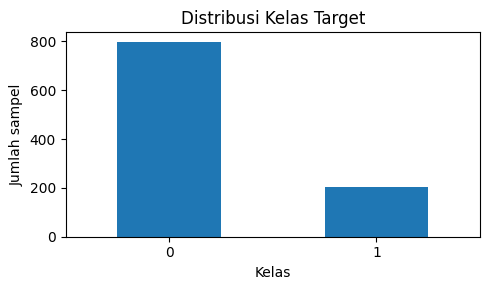

In [3]:
print("Distribusi kelas target:")
distribusi = y.value_counts().sort_index().rename_axis("Kelas").to_frame("Jumlah")
distribusi["Persentase (%)"] = (distribusi["Jumlah"] / len(y) * 100).round(2)
display(distribusi)

print("Total missing values pada fitur:", int(X.isna().sum().sum()))
print("\nMissing values per fitur:")
display(X.isna().sum().rename("Jumlah Missing").to_frame())

plt.figure(figsize=(5, 3))
y.value_counts().sort_index().plot(kind="bar")
plt.title("Distribusi Kelas Target")
plt.xlabel("Kelas")
plt.ylabel("Jumlah sampel")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Split data dengan stratifikasi

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("\nProporsi kelas pada seluruh data:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))
print("\nProporsi kelas pada data train:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))
print("\nProporsi kelas pada data test:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))


Ukuran X_train: (800, 10)
Ukuran X_test : (200, 10)

Proporsi kelas pada seluruh data:
Target
0    79.7
1    20.3
Name: proportion, dtype: float64

Proporsi kelas pada data train:
Target
0    79.75
1    20.25
Name: proportion, dtype: float64

Proporsi kelas pada data test:
Target
0    79.5
1    20.5
Name: proportion, dtype: float64


## 5. Memeriksa kandidat outlier pada data train

,Fitur,Batas bawah IQR,Batas atas IQR,Kandidat outlier
0,Fitur_1,-3.871,1.889,12
1,Fitur_2,-3.716,4.080,7
2,Fitur_3,-5.014,4.811,3
3,Fitur_4,-2.839,2.775,6
4,Fitur_5,-5.566,4.175,4
5,Fitur_6,-4.749,8.201,3
6,Fitur_7,-2.967,2.876,2
7,Fitur_8,-4.852,4.935,4
8,Fitur_9,-4.660,6.347,12
9,Fitur_10,-5.363,4.059,4


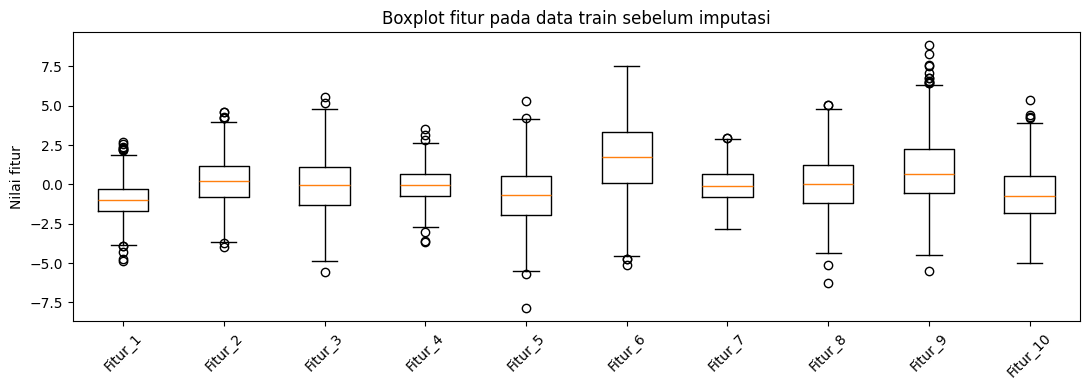

Catatan: outlier IQR adalah kandidat untuk diperiksa, bukan otomatis kesalahan data.


In [5]:
# Deteksi kandidat outlier menggunakan aturan IQR.
# Pemeriksaan ini hanya dilakukan pada data train. Kandidat tidak otomatis dihapus.
ringkasan_outlier = []
for kolom in X_train.columns:
    nilai = X_train[kolom].dropna()
    q1 = nilai.quantile(0.25)
    q3 = nilai.quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah_kandidat = int(((nilai < batas_bawah) | (nilai > batas_atas)).sum())
    ringkasan_outlier.append({
        "Fitur": kolom,
        "Batas bawah IQR": round(batas_bawah, 3),
        "Batas atas IQR": round(batas_atas, 3),
        "Kandidat outlier": jumlah_kandidat
    })

tabel_outlier = pd.DataFrame(ringkasan_outlier)
display(tabel_outlier)

plt.figure(figsize=(11, 4))
plt.boxplot([X_train[k].dropna().to_numpy() for k in X_train.columns])
plt.xticks(range(1, len(X_train.columns) + 1), X_train.columns, rotation=45)
plt.title("Boxplot fitur pada data train sebelum imputasi")
plt.ylabel("Nilai fitur")
plt.tight_layout()
plt.show()

print("Catatan: outlier IQR adalah kandidat untuk diperiksa, bukan otomatis kesalahan data.")


## 6. Imputasi missing values dengan KNN Imputer

In [6]:
# Imputer hanya di-fit pada data train untuk mencegah data leakage.
imputer = KNNImputer(n_neighbors=5)
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Jumlah missing pada X_train sebelum imputasi:", int(X_train.isna().sum().sum()))
print("Jumlah missing setelah imputasi train:", int(np.isnan(X_train_imputed).sum()))
print("Jumlah missing setelah transform test:", int(np.isnan(X_test_imputed).sum()))


Jumlah missing pada X_train sebelum imputasi: 239
Jumlah missing setelah imputasi train: 0
Jumlah missing setelah transform test: 0


## 7. Menyamakan skala fitur

In [7]:
# Scaler juga hanya di-fit pada data train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing selesai.")
print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)


Preprocessing selesai.
Train: (800, 10) | Test: (200, 10)


## 8. Melatih tiga pendekatan: baseline, SMOTE, dan class weight

In [8]:
# A. Baseline: Logistic Regression tanpa resampling dan tanpa class weight
model_baseline = LogisticRegression(max_iter=1000, random_state=42)
model_baseline.fit(X_train_scaled, y_train)
y_pred_baseline = model_baseline.predict(X_test_scaled)

# B. SMOTE: resampling dilakukan hanya pada data train
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
model_smote = LogisticRegression(max_iter=1000, random_state=42)
model_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = model_smote.predict(X_test_scaled)

# C. Class weight: memberi bobot lebih besar pada kelas yang lebih jarang
model_weight = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model_weight.fit(X_train_scaled, y_train)
y_pred_weight = model_weight.predict(X_test_scaled)

print("Jumlah kelas pada data train sebelum SMOTE:")
print(y_train.value_counts().sort_index())
print("\nJumlah kelas pada data train setelah SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())
print("\nCatatan: test set tidak pernah di-resample.")


Jumlah kelas pada data train sebelum SMOTE:
Target
0    638
1    162
Name: count, dtype: int64

Jumlah kelas pada data train setelah SMOTE:
Target
0    638
1    638
Name: count, dtype: int64

Catatan: test set tidak pernah di-resample.


## 9. Membandingkan metrik evaluasi

In [9]:
prediksi = {
    "Baseline": y_pred_baseline,
    "SMOTE": y_pred_smote,
    "Class Weight": y_pred_weight
}

baris_hasil = []
for nama, y_pred in prediksi.items():
    baris_hasil.append({
        "Metode": nama,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision (kelas 1)": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall (kelas 1)": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score (kelas 1)": round(f1_score(y_test, y_pred, zero_division=0), 4)
    })

hasil = pd.DataFrame(baris_hasil).sort_values("F1-Score (kelas 1)", ascending=False).reset_index(drop=True)
display(hasil)


,Metode,Accuracy,Precision (kelas 1),Recall (kelas 1),F1-Score (kelas 1)
0,Class Weight,0.750,0.4400,0.8049,0.5690
1,Baseline,0.845,0.6667,0.4878,0.5634
2,SMOTE,0.725,0.4054,0.7317,0.5217


## 10. Membaca confusion matrix

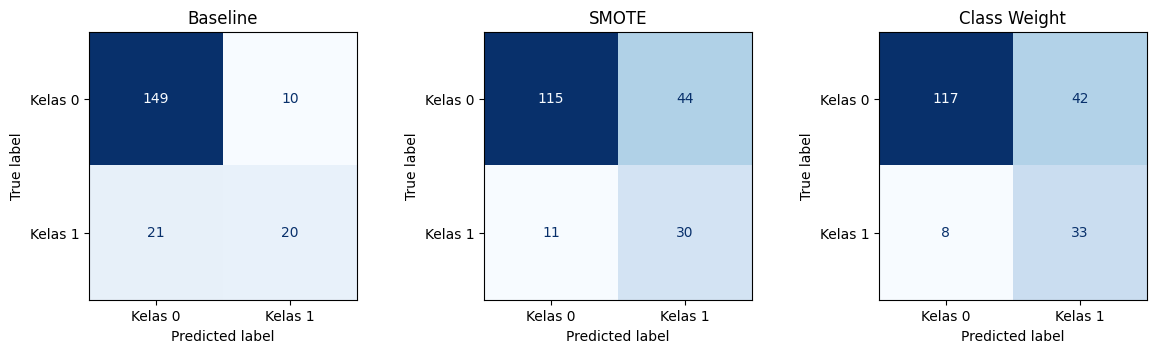

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (nama, y_pred) in zip(axes, prediksi.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Kelas 0", "Kelas 1"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(nama)
plt.tight_layout()
plt.show()


## 11. Kesimpulan dan keputusan

In [11]:
# Ringkasan otomatis berdasarkan nilai yang benar-benar diperoleh.
best_f1 = hasil.loc[hasil["F1-Score (kelas 1)"].idxmax()]
best_recall = hasil.loc[hasil["Recall (kelas 1)"].idxmax()]

print(f"Metode dengan F1-score tertinggi: {best_f1['Metode']} ({best_f1['F1-Score (kelas 1)']:.4f})")
print(f"Metode dengan recall kelas 1 tertinggi: {best_recall['Metode']} ({best_recall['Recall (kelas 1)']:.4f})")
print("\nPanduan keputusan:")
print("- Pilih F1-score tinggi bila ingin keseimbangan precision dan recall.")
print("- Utamakan recall bila melewatkan kelas 1 (false negative) merupakan kesalahan yang paling mahal.")
print("- Bandingkan juga precision dan accuracy; jangan memilih metode dari accuracy saja.")
print("- SMOTE diterapkan hanya pada data train, sedangkan evaluasi dilakukan pada test set asli.")


Metode dengan F1-score tertinggi: Class Weight (0.5690)
Metode dengan recall kelas 1 tertinggi: Class Weight (0.8049)

Panduan keputusan:
- Pilih F1-score tinggi bila ingin keseimbangan precision dan recall.
- Utamakan recall bila melewatkan kelas 1 (false negative) merupakan kesalahan yang paling mahal.
- Bandingkan juga precision dan accuracy; jangan memilih metode dari accuracy saja.
- SMOTE diterapkan hanya pada data train, sedangkan evaluasi dilakukan pada test set asli.
